In [ ]:
!pip install -q torch torchvision numpy matplotlib pillow ultralytics

In [2]:
import io
import time
import urllib.request
import warnings

import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision
from PIL import Image
from ultralytics import YOLO
from ultralytics.data.augment import LetterBox

warnings.filterwarnings("ignore")

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available() else "cpu"
)
MODEL_NAME = "../data/weights/yolo26n.pt"
IMAGE_URL = "https://ultralytics.com/images/bus.jpg"
IMG_SIZE = 640
SEED = 42
torch.manual_seed(SEED)
print(f"DEVICE = {DEVICE}")

DEVICE = mps


# 1) Object Detection

- A detector maps an image to a variable-length set of `(box, class, score)` triples.
- The network itself is a dense predictor: every cell of a feature-map grid emits one candidate box and a score per class, so a 640 × 640 image yields thousands of candidates for a handful of objects.
- Detection is therefore three small pieces of geometry around a CNN: a **box parameterisation** the network can regress, an **overlap measure** (IoU), and a rule that turns many overlapping candidates into one box per object (**NMS**, or a one-to-one training assignment that makes NMS unnecessary).
- The pieces are written from scratch and run on the raw outputs of a real pretrained detector, YOLO26-nano.

| Approach | Duplicates handled by | Examples |
|---|---|---|
| Two-stage | proposals + per-class NMS | Faster R-CNN |
| One-stage, one-to-many | NMS at inference | YOLOv3–v11, FCOS, RetinaNet |
| Set prediction, one-to-one | Hungarian matching in training | DETR, RT-DETR, RF-DETR |
| Dual-head | one-to-many head for training signal, one-to-one head at inference | YOLOv10, YOLO26 |

# 2) Boxes and Intersection over Union

Two box formats appear everywhere:

| Format | Fields | Typical use |
|--------|--------|-------------|
| `xyxy` | top-left and bottom-right corners | IoU, NMS, evaluation |
| `cxcywh` | centre, width, height | regression targets, augmentation |

For boxes $A, B$ in `xyxy`,

$$\text{IoU}(A, B) = \frac{|A \cap B|}{|A| + |B| - |A \cap B|}, \qquad
|A \cap B| = \max(0, \min(x_2^A, x_2^B) - \max(x_1^A, x_1^B)) \cdot \max(0, \min(y_2^A, y_2^B) - \max(y_1^A, y_1^B)).$$

IoU is scale invariant and lies in $[0, 1]$. Evaluation counts a prediction as a true positive
when its IoU with an unmatched ground-truth box exceeds a threshold (0.5 for AP$_{50}$; COCO AP
averages thresholds 0.50:0.05:0.95). The pairwise $N \times M$ IoU matrix is computed by
broadcasting, never by a double loop.

In [3]:
def xyxy_to_cxcywh(boxes: torch.Tensor) -> torch.Tensor:
    """(..., 4) [x1, y1, x2, y2] -> (..., 4) [cx, cy, w, h]."""
    x1, y1, x2, y2 = boxes.unbind(-1)
    return torch.stack([(x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1], dim=-1)


def cxcywh_to_xyxy(boxes: torch.Tensor) -> torch.Tensor:
    """(..., 4) [cx, cy, w, h] -> (..., 4) [x1, y1, x2, y2]."""
    cx, cy, w, h = boxes.unbind(-1)
    return torch.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], dim=-1)


def box_iou(boxes1: torch.Tensor, boxes2: torch.Tensor) -> torch.Tensor:
    """Pairwise IoU. boxes1 (N, 4), boxes2 (M, 4) in xyxy -> (N, M)."""
    # (N, 1, 2) vs (1, M, 2) -> (N, M, 2)
    top_left = torch.max(boxes1[:, None, :2], boxes2[None, :, :2])
    bottom_right = torch.min(boxes1[:, None, 2:], boxes2[None, :, 2:])
    inter = (bottom_right - top_left).clamp(min=0).prod(-1)
    area1 = (boxes1[:, 2:] - boxes1[:, :2]).prod(-1)
    area2 = (boxes2[:, 2:] - boxes2[:, :2]).prod(-1)
    return inter / (area1[:, None] + area2[None, :] - inter)

In [4]:
# Example: convert boxes and verify round-trip
boxes_xyxy = torch.tensor([[10.0, 20.0, 50.0, 60.0], [100.0, 150.0, 200.0, 250.0]])
print("cxcywh:", xyxy_to_cxcywh(boxes_xyxy).tolist())
print(
    "round trip ok:",
    torch.allclose(cxcywh_to_xyxy(xyxy_to_cxcywh(boxes_xyxy)), boxes_xyxy),
)

# Example IoU cases: identical, partial, disjoint
ref = torch.tensor([[0.0, 0.0, 10.0, 10.0]])
others = torch.tensor(
    [[0.0, 0.0, 10.0, 10.0], [5.0, 5.0, 15.0, 15.0], [20.0, 20.0, 30.0, 30.0]]
)
ious = box_iou(ref, others)[0].tolist()
print("IoU identical / partial overlap / disjoint:", [round(v, 3) for v in ious])

# random boxes against torchvision's implementation
corners = torch.rand(200, 2, 2) * 500
random_boxes = torch.cat([corners.min(1).values, corners.max(1).values], dim=1)
ref_iou = torchvision.ops.box_iou(random_boxes, random_boxes)
diff = (box_iou(random_boxes, random_boxes) - ref_iou).abs().max()
print(f"max |ours - torchvision.ops.box_iou| on 200 x 200 pairs: {diff:.1e}")

cxcywh: [[30.0, 40.0, 40.0, 40.0], [150.0, 200.0, 100.0, 100.0]]
round trip ok: True
IoU identical / partial overlap / disjoint: [1.0, 0.143, 0.0]
max |ours - torchvision.ops.box_iou| on 200 x 200 pairs: 0.0e+00


# 3) Non-Maximum Suppression

A dense head fires on every grid cell that overlaps an object, so one object produces a cluster
of near-identical boxes. Greedy NMS keeps the top-scoring box, deletes every remaining box whose
IoU with it exceeds a threshold $\tau$, and repeats:

```
order = argsort(scores, descending)
while order not empty:
    keep  order[0]
    order = [j in order[1:] if IoU(box[order[0]], box[j]) <= τ]
```

$\tau$ trades recall on crowded scenes (two people standing close together have high IoU) against
leftover duplicates. NMS is run **per class**: a dog box must not suppress the overlapping
person box. The usual trick is to offset every box by `class_id × (max coordinate + 1)` so boxes
of different classes can never overlap, then run one class-agnostic NMS.

In [5]:
def nms(
    boxes: torch.Tensor, scores: torch.Tensor, iou_threshold: float
) -> torch.Tensor:
    """Greedy NMS. boxes (N, 4) xyxy, scores (N,) -> kept indices, by score."""
    order = scores.argsort(descending=True)
    keep = []
    while order.numel() > 0:
        best = order[0]
        keep.append(best)
        # (1, 4) vs (num_left, 4) -> (num_left,)
        overlap = box_iou(boxes[best][None], boxes[order[1:]])[0]
        order = order[1:][overlap <= iou_threshold]
    return torch.stack(keep) if keep else torch.empty(0, dtype=torch.long)


def batched_nms(
    boxes: torch.Tensor,
    scores: torch.Tensor,
    classes: torch.Tensor,
    iou_threshold: float,
) -> torch.Tensor:
    """Per-class NMS by shifting each class into its own coordinate range."""
    offsets = classes.to(boxes.dtype) * (boxes.max() + 1)
    return nms(boxes + offsets[:, None], scores, iou_threshold)

In [6]:
# Create random candidate boxes, scores, and classes
centres = torch.rand(300, 2) * 400
sizes = torch.rand(300, 2) * 80 + 20
cand_boxes = torch.cat([centres, centres + sizes], dim=1)
cand_scores = torch.rand(300)
cand_classes = torch.randint(0, 3, (300,))

# Compare our single-class NMS with torchvision's
ours = nms(cand_boxes, cand_scores, 0.5)
theirs = torchvision.ops.nms(cand_boxes, cand_scores, 0.5)
same = torch.equal(ours, theirs)
print(f"single class: kept {len(ours)} of 300, same as torchvision: {same}")

# Compare our batched NMS with torchvision's per-class
ours_b = batched_nms(cand_boxes, cand_scores, cand_classes, 0.5)
theirs_b = torchvision.ops.batched_nms(cand_boxes, cand_scores, cand_classes, 0.5)
same = torch.equal(ours_b, theirs_b)
print(f"per class:    kept {len(ours_b)} of 300, same as torchvision: {same}")

single class: kept 246 of 300, same as torchvision: True
per class:    kept 280 of 300, same as torchvision: True


# 4) Feature Grid to Boxes

Modern YOLOs (v8 onward) are **anchor-free**. The backbone produces feature maps at strides
$s \in \{8, 16, 32\}$; every cell $(i, j)$ of the map at stride $s$ is an *anchor point* at
$(j + 0.5,\ i + 0.5)$ in grid units. At each point the head regresses four non-negative distances
$(l, t, r, b)$ to the box edges and one logit per class:

$$x_1 = s\,(c_x - l), \quad y_1 = s\,(c_y - t), \quad x_2 = s\,(c_x + r), \quad y_2 = s\,(c_y + b),
\qquad p_k = \sigma(z_k).$$

At 640 px that is $80^2 + 40^2 + 20^2 = 8400$ candidates. YOLO26 regresses the distances directly
(`reg_max = 1`); YOLOv8–v11 instead predicted a 16-bin distribution per edge (Distribution Focal
Loss) and took its expectation. Older YOLOs (v2–v5) predicted offsets from fixed anchor boxes,
$b_w = p_w e^{t_w}$, which needed anchor sizes tuned per dataset.

```
feature map  (batch_num, 4 + num_classes, H_s, W_s)   for s in 8, 16, 32
  flatten -> (batch_num, 4 + num_classes, 8400)
  boxes    = decode(ltrb, anchor_points, strides)      (8400, 4)   xyxy pixels
  scores   = sigmoid(class logits)                     (8400, 80)
```

In [7]:
def make_anchor_points(
    grid_sizes: list[tuple[int, int]], strides: list[int]
) -> tuple[torch.Tensor, torch.Tensor]:
    """Cell centres in grid units (num_points, 2) and their strides (num_points, 1)."""
    points, point_strides = [], []
    for (h, w), s in zip(grid_sizes, strides):
        ys, xs = torch.meshgrid(
            torch.arange(h) + 0.5, torch.arange(w) + 0.5, indexing="ij"
        )
        points.append(torch.stack([xs, ys], dim=-1).reshape(-1, 2))
        point_strides.append(torch.full((h * w, 1), float(s)))
    return torch.cat(points), torch.cat(point_strides)


def decode_ltrb(
    ltrb: torch.Tensor, points: torch.Tensor, point_strides: torch.Tensor
) -> torch.Tensor:
    """ltrb (num_points, 4) in grid units -> boxes (num_points, 4) xyxy in pixels."""
    top_left = points - ltrb[:, :2]
    bottom_right = points + ltrb[:, 2:]
    return torch.cat([top_left, bottom_right], dim=1) * point_strides


# Build anchor grids and compute anchor points/strides
STRIDES = [8, 16, 32]
grid_sizes = [(IMG_SIZE // s, IMG_SIZE // s) for s in STRIDES]
anchor_points, anchor_strides = make_anchor_points(grid_sizes, STRIDES)
print(f"grids {grid_sizes} -> {len(anchor_points)} anchor points")

# a ground-truth box encoded at the stride-16 point under its centre, then decoded back
gt = torch.tensor([[200.0, 120.0, 330.0, 300.0]])
idx = 80 * 80 + int(210 // 16) * 40 + int(265 // 16)
point, s = anchor_points[idx], anchor_strides[idx]
target = torch.cat([point - gt[0, :2] / s, gt[0, 2:] / s - point])[None]
print(f"point {point.tolist()} stride {int(s)} -> target ltrb {target[0].tolist()}")
print("decoded:", decode_ltrb(target, point[None], s[None]).tolist())

grids [(80, 80), (40, 40), (20, 20)] -> 8400 anchor points
point [16.5, 13.5] stride 16 -> target ltrb [4.0, 6.0, 4.125, 5.25]
decoded: [[200.0, 120.0, 330.0, 300.0]]


# 5) A Real Detector: YOLO26-nano

- YOLO26 (Ultralytics, 2025–26) has two heads on the same features.

- The **one-to-many** head is trained with a task-aligned assigner that gives each object its top-$k$ anchor points, which is a rich training signal but means several points fire per object at inference, so its output needs NMS.

- The **one-to-one** head is trained with an assignment that gives each object exactly one point; at inference only this head is read, and the top-scoring candidates are already final.

- YOLO26 also drops Distribution Focal Loss and trains with MuSGD, a Muon-style optimiser.

- The 2.6M-parameter nano checkpoint runs below on one COCO-style street photo.

- The raw one-to-many distances are decoded with `decode_ltrb` and compared with the model's own decoder, then post-processed both ways.

In [8]:
# Load YOLO model, move to device, and show summary
yolo = YOLO(MODEL_NAME)
net = yolo.model.eval().to(DEVICE)
head = net.model[-1]
num_params = sum(p.numel() for p in net.parameters())
print(f"{type(head).__name__} head | strides {head.stride.tolist()}", end="")
print(f" | reg_max {head.reg_max}")
print(f"{num_params / 1e6:.1f} M params | {len(yolo.names)} COCO classes")

# Download and letterbox the image, convert to tensor
raw_bytes = urllib.request.urlopen(IMAGE_URL).read()
image = np.array(Image.open(io.BytesIO(raw_bytes)).convert("RGB"))
# (H, W, 3) uint8 -> letterboxed (640, 640, 3) -> (1, 3, 640, 640) in [0, 1]
letterboxed = LetterBox((IMG_SIZE, IMG_SIZE), auto=False)(image=image)
x = torch.from_numpy(letterboxed).permute(2, 0, 1)[None].float().div(255).to(DEVICE)

# Run model forward pass and time the inference
with torch.no_grad():
    head.end2end = False
    start = time.time()
    decoded, raw = net(x)
    elapsed = time.time() - start
print(f"image {image.shape} -> input {tuple(x.shape)} | forward {elapsed:.2f} s")

# raw one-to-many outputs: ltrb distances (4, 8400) and class logits (80, 8400)
raw_ltrb = raw["one2many"]["boxes"][0].T.cpu()
raw_logits = raw["one2many"]["scores"][0].T.cpu()
ours_boxes = decode_ltrb(raw_ltrb, anchor_points, anchor_strides)
model_boxes = cxcywh_to_xyxy(decoded[0, :4].T.cpu())
box_err = (ours_boxes - model_boxes).abs().max()
score_err = (raw_logits.sigmoid() - decoded[0, 4:].T.cpu()).abs().max()
print(f"max |decode_ltrb - model decoder| = {box_err:.1e} px")
print(f"max |sigmoid(logits) - model scores| = {score_err:.1e}")

Detect head | strides [8.0, 16.0, 32.0] | reg_max 1
2.6 M params | 80 COCO classes


image (1080, 810, 3) -> input (1, 3, 640, 640) | forward 0.33 s
max |decode_ltrb - model decoder| = 6.1e-05 px
max |sigmoid(logits) - model scores| = 1.2e-07


In [9]:
SCORE_THRESHOLD = 0.25
NMS_IOU = 0.7

# one-to-many route: best class per point -> threshold -> per-class NMS
scores, classes = raw_logits.sigmoid().max(dim=1)
candidates = scores > SCORE_THRESHOLD
keep = batched_nms(
    ours_boxes[candidates], scores[candidates], classes[candidates], NMS_IOU
)
o2m_boxes = ours_boxes[candidates][keep]
o2m_scores, o2m_classes = scores[candidates][keep], classes[candidates][keep]

# one-to-one route: top-k over all (point, class) scores, no NMS
with torch.no_grad():
    head.end2end = True
    final = net(x)[0][0].cpu()
o2o = final[final[:, 4] > SCORE_THRESHOLD]

# Print counts, compare one-to-one vs one-to-many results
print(f"anchor points scored:                 {len(scores):,}")
print(
    f"one-to-many above {SCORE_THRESHOLD}:               {int(candidates.sum())} boxes"
)
print(f"  after batched_nms:                  {len(o2m_boxes)} boxes")
print(f"one-to-one above {SCORE_THRESHOLD}, no NMS:        {len(o2o)} boxes")
matched_iou = box_iou(o2o[:, :4], o2m_boxes).max(dim=1).values
print("best IoU of each one-to-one box with an NMS box:", end=" ")
print([round(v, 2) for v in matched_iou.tolist()])
for row in o2o:
    print(f"  {yolo.names[int(row[5])]:<8} score {row[4]:.2f}")

anchor points scored:                 8,400
one-to-many above 0.25:               48 boxes
  after batched_nms:                  5 boxes
one-to-one above 0.25, no NMS:        5 boxes
best IoU of each one-to-one box with an NMS box: [0.98, 0.99, 0.98, 0.99, 0.91]
  bus      score 0.93
  person   score 0.92
  person   score 0.90
  person   score 0.86
  person   score 0.52


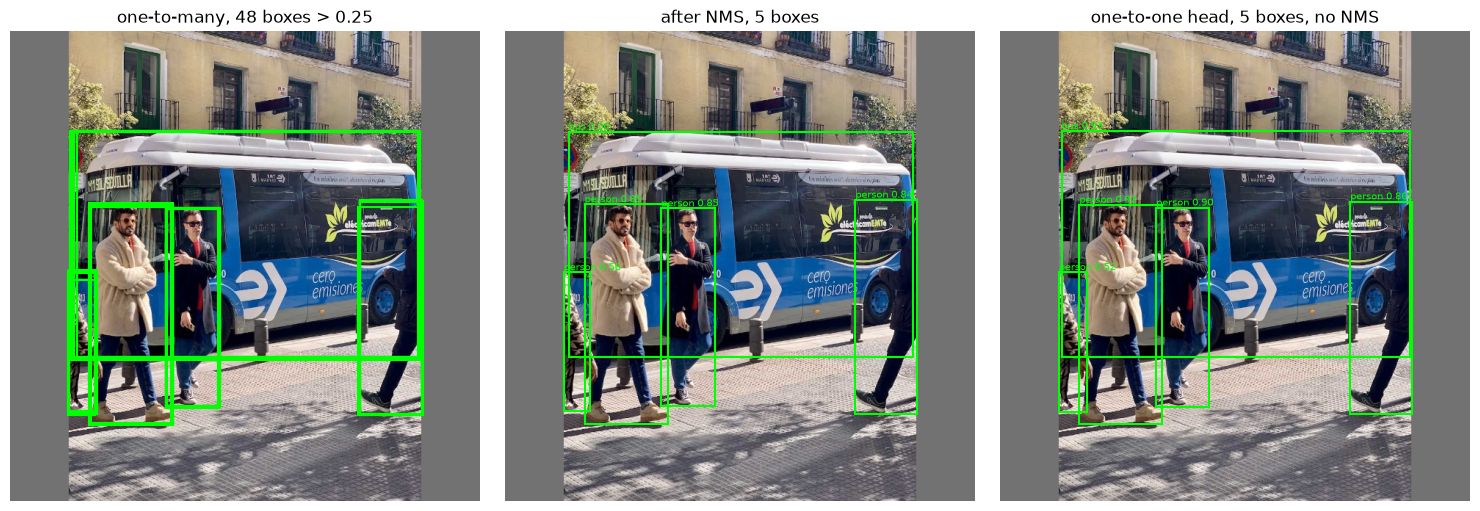

In [10]:
def draw(ax: plt.Axes, boxes: torch.Tensor, labels: list[str], title: str) -> None:
    """Draw xyxy boxes with labels on the letterboxed image."""
    ax.imshow(letterboxed)
    for (x1, y1, x2, y2), label in zip(boxes.tolist(), labels):
        ax.add_patch(
            patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, lw=1.5, ec="lime")
        )
        ax.text(x1, y1 - 3, label, color="lime", fontsize=7)
    ax.set_title(title)
    ax.axis("off")


# Plot raw candidates, NMS results, and one-to-one boxes
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
raw_cand = ours_boxes[candidates]
title = f"one-to-many, {len(raw_cand)} boxes > {SCORE_THRESHOLD}"
draw(axes[0], raw_cand, [""] * len(raw_cand), title)
draw(
    axes[1],
    o2m_boxes,
    [f"{yolo.names[int(c)]} {s:.2f}" for c, s in zip(o2m_classes, o2m_scores)],
    f"after NMS, {len(o2m_boxes)} boxes",
)
draw(
    axes[2],
    o2o[:, :4],
    [f"{yolo.names[int(r[5])]} {r[4]:.2f}" for r in o2o],
    f"one-to-one head, {len(o2o)} boxes, no NMS",
)
plt.tight_layout()
plt.show()

# Summary

| Knob | Typical value | Effect |
|---|---|---|
| Score threshold | 0.25 for display, 0.001 for mAP evaluation | Evaluation sweeps the whole precision–recall curve, so it keeps almost everything |
| NMS IoU $\tau$ | 0.45–0.7 | Lower merges nearby objects (crowds), higher leaves duplicates |
| Max detections | 300 | Caps post-processing cost and the AP computation |
| Input size | 640 (letterboxed, aspect kept) | Small objects need larger inputs or the stride-8 level |

- **Latency.** NMS is sequential and data-dependent: its cost grows with the number of candidates,
  which is why it dominates latency on busy scenes and is awkward to export (TensorRT, CoreML).
  One-to-one heads remove it; the price is a weaker training signal per object, which YOLOv10 and
  YOLO26 recover by training the one-to-many head alongside.
- **Soft-NMS / class-agnostic NMS.** Soft-NMS decays overlapping scores instead of deleting them
  (helps crowds); class-agnostic NMS is used when one object may get two similar class labels.
- **Evaluation.** COCO mAP matches predictions to ground truth greedily by score with IoU
  thresholds 0.50:0.95 and averages precision over 101 recall points per class
  (`pycocotools`, `torchmetrics.detection.MeanAveragePrecision`).
- **Licensing.** Ultralytics models are AGPL-3.0; RF-DETR and RT-DETR are Apache-2.0
  alternatives with one-to-one heads.

| Piece | Formula / rule | Checked against |
|---|---|---|
| Box formats | `xyxy` ↔ `cxcywh` | round trip |
| IoU | $\lvert A \cap B \rvert / \lvert A \cup B \rvert$, broadcast to $N \times M$ | `torchvision.ops.box_iou` |
| NMS | greedy keep-best, drop IoU $> \tau$; per class by coordinate offset | `torchvision.ops.nms`, `batched_nms` |
| Anchor-free decode | $x_1 = s(c_x - l)$, … over strides 8/16/32 | YOLO26's own decoder |
| One-to-one head | top-$k$ scores are final, no NMS | finds the same objects as one-to-many + NMS |